# 04 – Modeller: Logistic Regression ve KNN

Bu notebook **makine öğrenmesi modelleri** bölümünün ilk kısmını kapsar: Logistic Regression ve KNN için hiperparametre araması, overfitting kontrolü ve öğrenme eğrileri.

- **Veri bölme:** %80 train / %20 test (02'de yapıldı). Hiperparametre seçimi train üzerinde **5 katlı stratified cross-validation** ile yapılır, her katta ayrılan parça validation verisidir.
- **Seçim metriği:** Phishing sınıfının F1 skoru.
- **Test verisi** bu notebook'ta kullanılmaz, 06'da en iyi modellerle bir kez kullanılacaktır.
- **SMOTE** kullanılmaz (03'te fayda sağlamadığı gösterildi).

Girdi: `outputs/X_train.csv`, `outputs/y_train.csv`
Çıktı: `outputs/cv_results_lr.csv`, `cv_results_knn.csv`, `en_iyi_parametreler.csv`, `outputs/models/best_lr.pkl`, `best_knn.pkl`

## 1. Kurulum

In [3]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/models", exist_ok=True)

def grafik_kaydet(ad):
    plt.savefig(f"outputs/figures/{ad}.png", dpi=150, bbox_inches="tight")

## 2. Verinin yüklenmesi

In [5]:
X_train = pd.read_csv("outputs/X_train.csv")
y_train = pd.read_csv("outputs/y_train.csv").squeeze()   

print("Train:", X_train.shape)

Train: (4617, 31)


## 3. Değerlendirme ayarları

CV katları 02 ve 03'teki ile aynıdır (`random_state=42`), böylece tüm modeller aynı validation parçalarında değerlendirilir. Seçim F1'e göre yapılır, diğer metrikler karşılaştırma için kaydedilir.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skorlar = {
    "f1": make_scorer(f1_score, pos_label=-1),          # ana metrik: phishing F1
    "recall": make_scorer(recall_score, pos_label=-1),
    "precision": make_scorer(precision_score, pos_label=-1),
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
}

## 4. Yardımcı fonksiyonlar

- `ara_ve_kaydet`: `GridSearchCV` ile tüm parametre kombinasyonlarını dener. Sonuçları (`cv_results_`) CSV'ye, en iyi modeli `.pkl` dosyasına kaydeder. **Dosyalar zaten varsa arama tekrarlanmaz**, kayıtlı sonuçlar yüklenir. Yeniden aramak için `yeniden=True` verilir.
- `ozet_kaydet`: Her modelin en iyi parametrelerini ve skorlarını `en_iyi_parametreler.csv` dosyasında toplar (05 de bu dosyaya yazar).

> Not: `GridSearchCV` çıktısındaki `mean_test_f1`, `split0_test_f1` gibi sütun adlarındaki "test" ifadesi scikit-learn'ün isimlendirmesidir. Bu değerler **validation** skorlarıdır.

In [7]:
def ara_ve_kaydet(ad, model, param_grid, yeniden=False):
    csv_yolu = f"outputs/cv_results_{ad}.csv"
    model_yolu = f"outputs/models/best_{ad}.pkl"

    if os.path.exists(csv_yolu) and os.path.exists(model_yolu) and not yeniden:
        print(f"{ad}: kayıtlı sonuçlar yüklendi (yeniden eğitilmedi)")
        return pd.read_csv(csv_yolu), joblib.load(model_yolu)

    # refit="f1": en iyi parametre validation F1'e göre seçilir ve model tüm train ile yeniden eğitilir
    gs = GridSearchCV(model, param_grid, scoring=skorlar, refit="f1", cv=cv,
                      return_train_score=True, n_jobs=-1)
    gs.fit(X_train, y_train)

    sonuc = pd.DataFrame(gs.cv_results_)
    sonuc.to_csv(csv_yolu, index=False)
    joblib.dump(gs.best_estimator_, model_yolu)
    print(f"{ad}: {len(sonuc)} kombinasyon denendi, en iyi validation F1 = {gs.best_score_:.4f}")
    return sonuc, gs.best_estimator_

def en_iyi_satir(sonuc):
    # Validation F1'e göre 1. sıradaki parametre kombinasyonu
    return sonuc.loc[sonuc["rank_test_f1"].idxmin()]

def ozet_kaydet(ad, sonuc):
    s = en_iyi_satir(sonuc)
    satir = {"model": ad, "parametreler": s["params"],
             **{f"val_{m}": round(s[f"mean_test_{m}"], 4) for m in skorlar},
             "train_f1": round(s["mean_train_f1"], 4),
             "fit_suresi_sn": round(s["mean_fit_time"], 3)}
    yol = "outputs/en_iyi_parametreler.csv"
    ozet = pd.read_csv(yol) if os.path.exists(yol) else pd.DataFrame()
    if len(ozet):
        ozet = ozet[ozet["model"] != ad]      # aynı model daha önce yazıldıysa eski satırı sil
    ozet = pd.concat([ozet, pd.DataFrame([satir])], ignore_index=True)
    ozet.to_csv(yol, index=False)
    return pd.DataFrame([satir])

## 5. Logistic Regression

Doğrusal bir sınıflandırıcıdır. Denenen parametreler:
- `C`: düzenlileştirme gücünün tersi. Küçük C güçlü düzenlileştirme demektir ve overfitting'i azaltır.
- `penalty`: `l1` bazı katsayıları sıfırlayarak özellik seçimi yapar, `l2` katsayıları küçültür.

Katsayı tabanlı olduğu için özellikler pipeline içinde standartlaştırılır. Ölçekleyici her CV katında yalnızca eğitim kısmına fit edilir.

In [8]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(solver="liblinear", max_iter=2000)),
])
lr_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
}
lr_sonuc, best_lr = ara_ve_kaydet("lr", lr_model, lr_grid)
ozet_kaydet("lr", lr_sonuc)

lr: 12 kombinasyon denendi, en iyi validation F1 = 0.9286


C:\Users\Zeynep\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,model,parametreler,val_f1,val_recall,val_precision,val_accuracy,val_roc_auc,train_f1,fit_suresi_sn
0,lr,"{'model__C': 0.1, 'model__penalty': 'l2'}",0.9286,0.9243,0.9333,0.9268,0.9789,0.9288,0.123


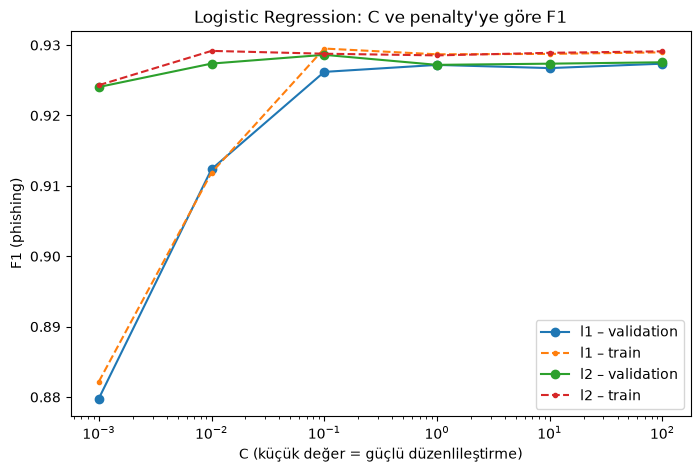

In [9]:
# Parametrelere göre validation (düz çizgi) ve train (kesikli çizgi) F1
fig, ax = plt.subplots(figsize=(8, 5))
for penalty, grup in lr_sonuc.groupby("param_model__penalty"):
    grup = grup.sort_values("param_model__C")
    ax.plot(grup["param_model__C"], grup["mean_test_f1"], marker="o", label=f"{penalty} – validation")
    ax.plot(grup["param_model__C"], grup["mean_train_f1"], marker=".", linestyle="--", label=f"{penalty} – train")
ax.set_xscale("log")
ax.set_xlabel("C (küçük değer = güçlü düzenlileştirme)")
ax.set_ylabel("F1 (phishing)")
ax.set_title("Logistic Regression: C ve penalty'ye göre F1")
ax.legend()
grafik_kaydet("lr_parametre_f1")
plt.show()

## 6. KNN (K-Nearest Neighbors)

Bir örneği, en yakın k komşusunun sınıflarına bakarak sınıflandırır. Denenen parametreler:
- `n_neighbors`: komşu sayısı. Küçük k overfitting'e, büyük k underfitting'e yatkındır.
- `weights`: `uniform` her komşuya eşit oy verir, `distance` yakın komşulara daha fazla ağırlık verir.
- `metric`: mesafe ölçüsü (öklid veya manhattan).

Mesafe tabanlı olduğu için standartlaştırma zorunludur.

In [10]:
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier()),
])
knn_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"],
}
knn_sonuc, best_knn = ara_ve_kaydet("knn", knn_model, knn_grid)
ozet_kaydet("knn", knn_sonuc)

knn: 36 kombinasyon denendi, en iyi validation F1 = 0.9494


,model,parametreler,val_f1,val_recall,val_precision,val_accuracy,val_roc_auc,train_f1,fit_suresi_sn
0,knn,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9494,0.9474,0.9514,0.948,0.9861,1.0,0.046


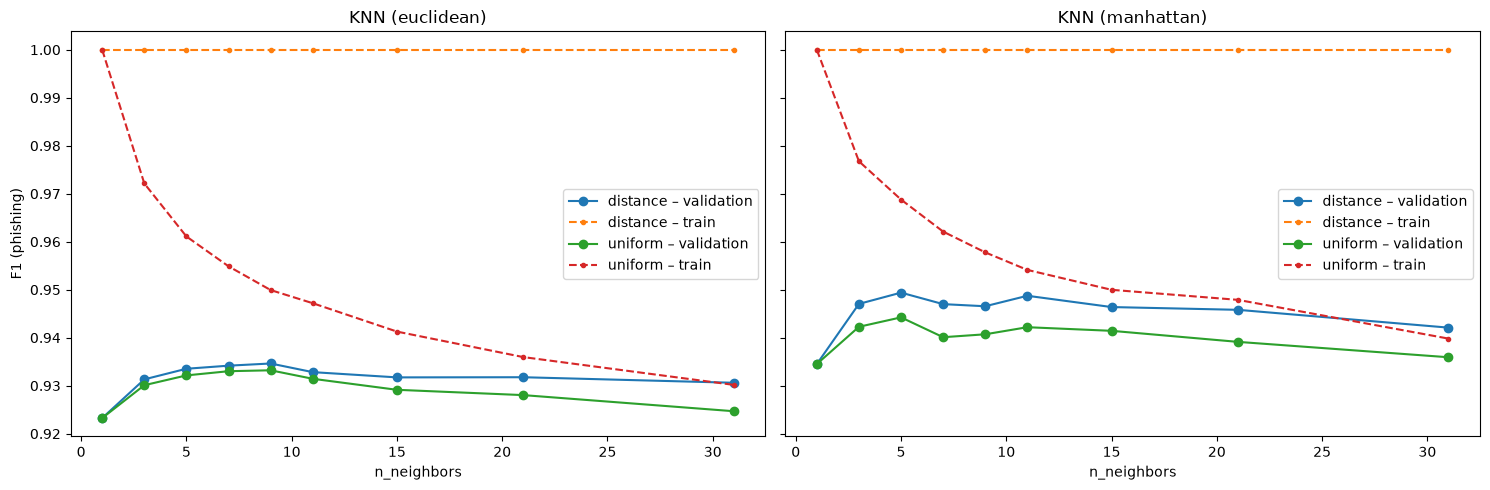

In [11]:
# Her mesafe ölçüsü için k ve weights'e göre validation (düz) ve train (kesikli) F1
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (metric, grup_m) in zip(axes, knn_sonuc.groupby("param_model__metric")):
    for weights, grup in grup_m.groupby("param_model__weights"):
        grup = grup.sort_values("param_model__n_neighbors")
        ax.plot(grup["param_model__n_neighbors"], grup["mean_test_f1"], marker="o", label=f"{weights} – validation")
        ax.plot(grup["param_model__n_neighbors"], grup["mean_train_f1"], marker=".", linestyle="--", label=f"{weights} – train")
    ax.set_title(f"KNN ({metric})")
    ax.set_xlabel("n_neighbors")
    ax.legend()
axes[0].set_ylabel("F1 (phishing)")
plt.tight_layout()
grafik_kaydet("knn_parametre_f1")
plt.show()

## 7. Overfitting kontrolü

En iyi parametrelerde train ve validation F1 karşılaştırılır. Aradaki fark büyükse model eğitim verisini ezberliyor (overfitting), iki skor da düşükse veriyi yeterince öğrenemiyor (underfitting) demektir.

> KNN'de `weights="distance"` seçildiğinde her eğitim örneği kendisine sıfır uzaklıkta olduğu için kendi etiketini belirler. Bu nedenle train F1 her k değerinde 1,0 çıkar. Bu, yöntemin doğası gereğidir. Modelin genelleme başarısı validation skoruyla değerlendirilir.

In [12]:
overfit = pd.DataFrame([{
    "model": ad,
    "train_f1": en_iyi_satir(s)["mean_train_f1"],
    "validation_f1": en_iyi_satir(s)["mean_test_f1"],
} for ad, s in [("Logistic Regression", lr_sonuc), ("KNN", knn_sonuc)]])
overfit["fark"] = overfit["train_f1"] - overfit["validation_f1"]
overfit.round(4)

,model,train_f1,validation_f1,fark
0,Logistic Regression,0.9288,0.9286,0.0002
1,KNN,1.0000,0.9494,0.0506


### 7.1 Öğrenme eğrileri

En iyi parametrelerle, eğitim verisi büyüdükçe train ve validation skorlarının nasıl değiştiği. Validation eğrisi train eğrisine yaklaşıyorsa daha fazla veri modeli iyileştirebilir. İki eğri birbirine yakın ama düşükse model yetersiz kalıyor demektir.

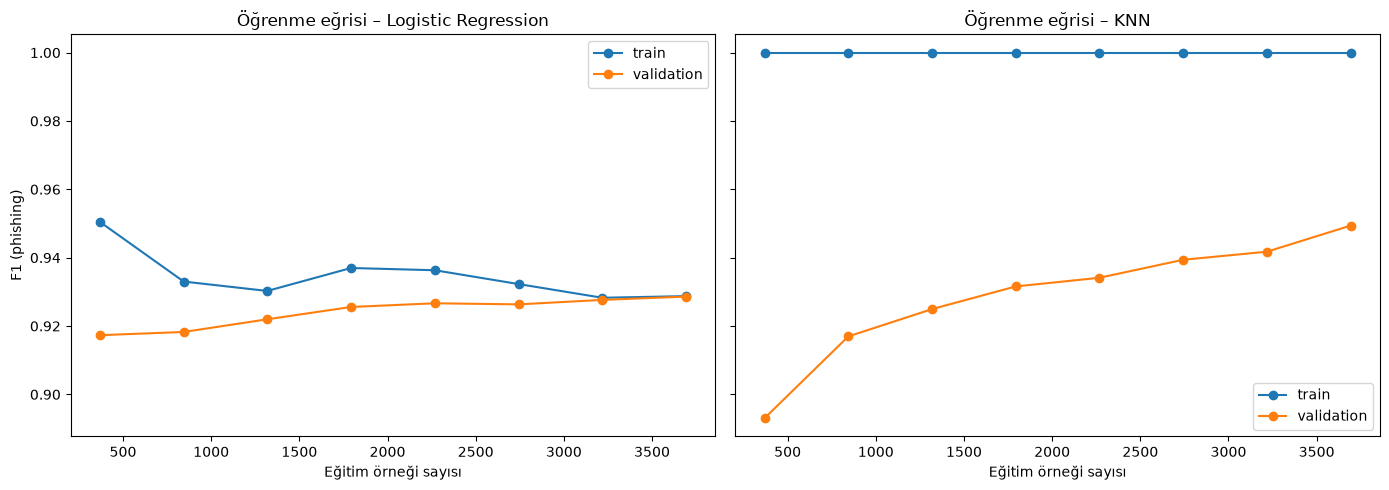

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (ad, model) in zip(axes, [("Logistic Regression", best_lr), ("KNN", best_knn)]):
    boyut, train_skor, val_skor = learning_curve(
        model, X_train, y_train, cv=cv, scoring=skorlar["f1"],
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    ax.plot(boyut, train_skor.mean(axis=1), marker="o", label="train")
    ax.plot(boyut, val_skor.mean(axis=1), marker="o", label="validation")
    ax.set_title(f"Öğrenme eğrisi – {ad}")
    ax.set_xlabel("Eğitim örneği sayısı")
    ax.legend()
axes[0].set_ylabel("F1 (phishing)")
plt.tight_layout()
grafik_kaydet("ogrenme_egrisi_lr_knn")
plt.show()

## 8. Özet

Bu notebook'ta seçilen en iyi parametreler ve validation skorları. 05'teki modeller de aynı dosyaya eklenecektir.

In [14]:
pd.read_csv("outputs/en_iyi_parametreler.csv")

,model,parametreler,val_f1,val_recall,val_precision,val_accuracy,val_roc_auc,train_f1,fit_suresi_sn
0,lr,"{'model__C': 0.1, 'model__penalty': 'l2'}",0.9286,0.9243,0.9333,0.9268,0.9789,0.9288,0.123
1,knn,"{'model__metric': 'manhattan', 'model__n_neigh...",0.9494,0.9474,0.9514,0.9480,0.9861,1.0000,0.046
